# ECHO — Investigation Notebook (solutions)
**Entangled Minds: The Quantathon · Qubits Qrew, NED**

Mandatory modules: **01, 03, 05**. Stretch modules: **06** (main) and **02** (extra).
Each module has: prediction → code → result → *what it proves*. The case report is in `Case_Report.md`.

### Setup — run first

In [1]:
%pip install qiskit qiskit-aer pylatexenc matplotlib --quiet

from qiskit import QuantumCircuit, transpile, QuantumRegister, ClassicalRegister
from qiskit_aer import AerSimulator
from qiskit.quantum_info import Statevector
from qiskit.visualization import plot_histogram, plot_bloch_multivector
import numpy as np, matplotlib.pyplot as plt

sim = AerSimulator(seed_simulator=42)   # fixed seed so results are repeatable
def run(circuit, shots=2000):
    return sim.run(transpile(circuit, sim), shots=shots).result().get_counts()


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: C:\Users\Arcz\AppData\Local\Temp\claude\D--Projects-Qunatathon\8db5a72b-6e4e-408b-bde6-175689a2ba17\scratchpad\venv\Scripts\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## Module 01 — The Gatekeeper (mandatory)
Note: Qiskit prints qubit 0 on the **right** of each result string.
### Bronze — a bit that is always 1, and a bit that is 50/50
Prediction: X → always `1`; H → about half `0`, half `1`.

In [2]:
qc = QuantumCircuit(1, 1); qc.x(0); qc.measure(0, 0)
print("Always 1:", run(qc))
qc = QuantumCircuit(1, 1); qc.h(0); qc.measure(0, 0)
print("50/50   :", run(qc))

Always 1: {'1': 2000}
50/50   : {'1': 988, '0': 1012}


**Proves:** X gives a certain result; H gives a genuine 50/50 superposition.
### Silver — looks uncertain but is secretly certain (H then H)
Prediction: |0⟩ → H → |+⟩ → H → |0⟩, so always `0`.

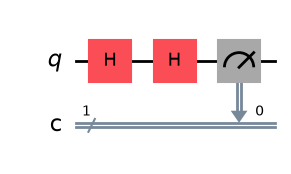

H,H: {'0': 2000}


In [3]:
qc = QuantumCircuit(1, 1); qc.h(0); qc.h(0); qc.measure(0, 0)
display(qc.draw("mpl"))
print("H,H:", run(qc))

**Proves:** after one H the qubit *looks* random but is in a definite state; the second H makes the amplitudes **interfere** (paths to `1` cancel), so the result is certain.
### Gold — vault code 101 from 000

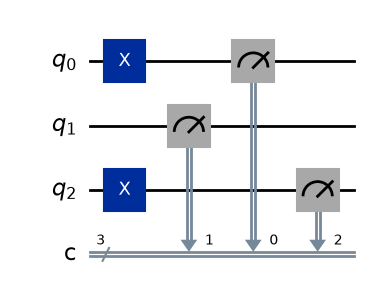

Vault code: {'101': 2000}


In [4]:
qc = QuantumCircuit(3, 3); qc.x(0); qc.x(2); qc.measure([0, 1, 2], [0, 1, 2])
display(qc.draw("mpl"))
print("Vault code:", run(qc))

**Proves:** we can build any exact classical pattern with X; qubit 0 is the rightmost character.

## Module 02 — The Honest Coin (extra stretch)
### Bronze — a fair quantum coin

In [5]:
qc = QuantumCircuit(1, 1); qc.h(0); qc.measure(0, 0)
print("Fair coin, 1000 shots:", run(qc, 1000))

Fair coin, 1000 shots:

 {'0': 514, '1': 486}


### Silver — the recovered seed circuit, run as-is

In [6]:
# the recovered seed circuit — run it as-is
seed = QuantumCircuit(1, 1)
seed.ry(1.159, 0)
seed.measure(0, 0)
print(run(seed))

{'0': 1415, '1': 585}


### Gold — size of the bias and how many shots are needed

In [7]:
N = 10000
c = run(seed, N)
p1 = c.get('1', 0) / N
z = (c.get('1', 0) - N/2) / (0.5 * np.sqrt(N))
print(f"Measured P(1) = {p1:.3f}   theory sin^2(1.159/2) = {np.sin(1.159/2)**2:.3f}")
print(f"Bias = {abs(p1-0.5):.3f}, z-score = {z:.1f}")
eps = abs(p1 - 0.5)
print("Shots needed to see this bias at 3 sigma:", int(np.ceil((3*0.5/eps)**2)))

Measured P(1) = 0.301   theory sin^2(1.159/2) = 0.300
Bias = 0.199, z-score = -39.7
Shots needed to see this bias at 3 sigma: 58


**Proves:** the 'random' seed is **not** fair — it gives `0` about 70% of the time (ry angle 1.159 instead of π/2 ≈ 1.571). The bias is ~0.20, z ≈ −40: impossible as bad luck. Only ~60 shots are needed to notice it at 3σ. Someone chose this angle — ECHO's trigger was biased, not random.

## Module 03 — The Two Observers (mandatory)
### Bronze — the pair that only agrees
Prediction: H on q0 then CNOT(0,1) → only `00` and `11`.

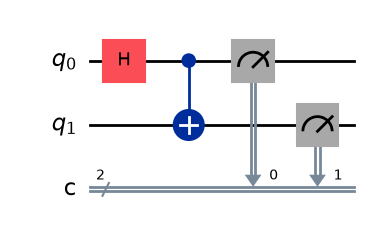

{'11': 1017, '00': 983}


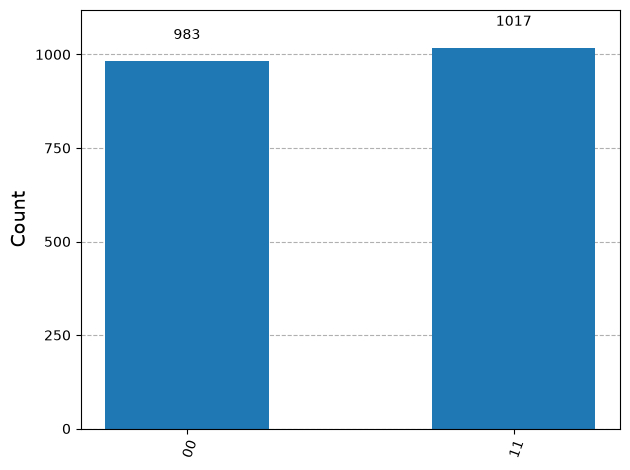

In [8]:
qc = QuantumCircuit(2, 2)
qc.h(0); qc.cx(0, 1)
qc.measure([0, 1], [0, 1])
display(qc.draw("mpl"))
counts = run(qc); print(counts)
plot_histogram(counts)

**Proves:** the detectors always agree — that is all it proves so far.
### Silver — a pre-agreed secret coin also always agrees
Qubit 2 is a hidden coin flip copied to both observers (never measured).

In [9]:
qc = QuantumCircuit(3, 2)
qc.h(2); qc.cx(2, 0); qc.cx(2, 1)
qc.measure([0, 1], [0, 1])
print("Shared secret:", run(qc))

Shared secret: {'11': 1017, '00': 983}


**Proves:** "always agreeing" does **not** prove a quantum link — a shared classical secret gives the same 00/11 pattern.
### Gold — an experiment that tells them apart: measure the other way (H on both before measuring)
Prediction: Bell pair still agrees (00/11); the shared coin becomes random (all four outcomes).

Bell pair, other basis : {'11': 1017, '00': 983}
Shared coin, other basis: {'11': 480, '01': 537, '00': 462, '10': 521}


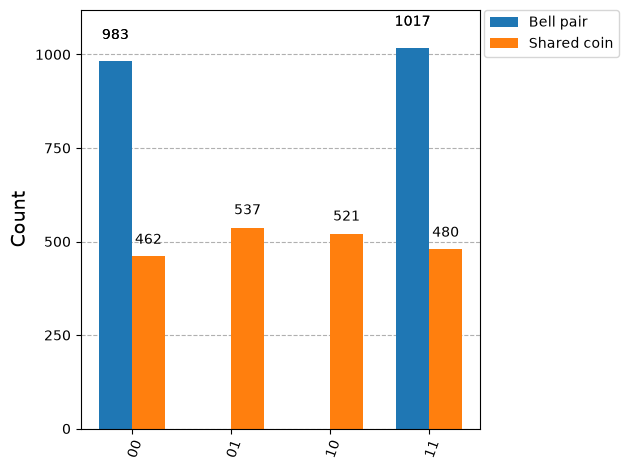

In [10]:
qc = QuantumCircuit(2, 2); qc.h(0); qc.cx(0, 1); qc.h(0); qc.h(1); qc.measure([0, 1], [0, 1])
bell_x = run(qc)
qc = QuantumCircuit(3, 2); qc.h(2); qc.cx(2, 0); qc.cx(2, 1); qc.h(0); qc.h(1); qc.measure([0, 1], [0, 1])
coin_x = run(qc)
print("Bell pair, other basis :", bell_x)
print("Shared coin, other basis:", coin_x)
plot_histogram([bell_x, coin_x], legend=["Bell pair", "Shared coin"])

**Proves:** the real entangled pair stays correlated in a second measurement direction; the simple shared secret does not.
### The crux — can the detectors send a message? (no-signalling)
Whatever Alice does to her qubit, Bob's own results should stay 50/50.

In [11]:
for alice in ["nothing", "h", "x", "measure"]:
    qc = QuantumCircuit(2, 2); qc.h(0); qc.cx(0, 1)
    if alice == "h": qc.h(0)
    if alice == "x": qc.x(0)
    if alice == "measure": qc.measure(0, 0)
    qc.measure(1, 1)
    c = run(qc, 4000)
    bob1 = sum(v for k, v in c.items() if k[0] == "1")   # leftmost char = qubit 1 = Bob
    print(f"Alice does {alice:8s} -> Bob sees 1 with probability {bob1/4000:.3f}")

Alice does nothing  -> Bob sees 1 with probability 0.504
Alice does h        -> Bob sees 1 with probability 0.504


Alice does x        -> Bob sees 1 with probability 0.504
Alice does measure  -> Bob sees 1 with probability 0.508


**Proves:** Bob's results are 50/50 no matter what Alice does → entanglement gives **correlation, not communication**. ECHO's detectors could agree but could never carry a message.

*Limitation:* with only H/X/CNOT we rule out a simple shared coin, not every classical model. A CHSH test (needs ry, below as a bonus) does:

In [12]:
def E(a, b, shots=20000):
    qc = QuantumCircuit(2, 2); qc.h(0); qc.cx(0, 1)
    qc.ry(-a, 0); qc.ry(-b, 1); qc.measure([0, 1], [0, 1])
    c = run(qc, shots); same = c.get('00', 0) + c.get('11', 0)
    return (2*same - shots) / shots
S = E(0, np.pi/4) + E(0, -np.pi/4) + E(np.pi/2, np.pi/4) - E(np.pi/2, -np.pi/4)
print(f"CHSH S = {S:.3f}  (classical limit 2, quantum max 2.83)")

CHSH S = 2.819  (classical limit 2, quantum max 2.83)


## Module 05 — The Damaged Message (mandatory)
### Bronze — majority vote on each triple

In [13]:
stream = "100011001001001011100110001011000000001100011011000111000000110000001000000111001010101011111111"
triples = [stream[i:i+3] for i in range(0, len(stream), 3)]
bits = "".join("1" if t.count("1") >= 2 else "0" for t in triples)
word = "".join(chr(int(bits[i:i+8], 2)) for i in range(0, len(bits), 8))
print("Decoded bits:", bits)
print("Message     :", word)
print("Triples corrected:", sum(t not in ("000", "111") for t in triples), "of", len(triples))

Decoded bits: 01000101010000110100100001001111
Message     : ECHO
Triples corrected: 20 of 32


**Proves:** majority vote recovers the message **ECHO** (if at most one flip per triple).
### Silver — where it fails

In [14]:
sent = "000"; received = "110"      # two flips
decoded = "1" if received.count("1") >= 2 else "0"
print(f"sent {sent} -> received {received} -> decoded {decoded}  (WRONG, and no warning)")

sent 000 -> received 110 -> decoded 1  (WRONG, and no warning)


**Proves:** with two flips in one triple, majority vote silently gives the wrong bit. Our decode depends on the promise "at most one flip per triple", which the data itself cannot verify.
### Gold
- Corrects **1** flip per triple; can **detect** up to **2** (the copies disagree); 3 flips are invisible (000 → 111).
- You cannot protect a qubit by copying it 3 times: **no-cloning** forbids copying an unknown state, and taking a vote would require **measuring**, which destroys the superposition. Phase errors are also invisible to a bit vote. Real quantum codes entangle (a|000⟩ + b|111⟩) and measure only parities.

## Module 06 — The Impossible Claim (main stretch)
The recovered circuit (unchanged): teleport the state ry(a)|0⟩, then the receiver undoes ry(a). If the state arrived, the receiver always reads `0` → 100%.

In [15]:
a = 1.0
def teleport(with_correction=True):
    q=QuantumRegister(3); c0=ClassicalRegister(1,'c0'); c1=ClassicalRegister(1,'c1'); co=ClassicalRegister(1,'co')
    qc=QuantumCircuit(q,c0,c1,co)
    qc.ry(a,q[0])
    qc.h(q[1]); qc.cx(q[1],q[2])
    qc.cx(q[0],q[1]); qc.h(q[0])
    qc.measure(q[0],c0); qc.measure(q[1],c1)
    if with_correction:
        with qc.if_test((c1,1)): qc.x(q[2])
        with qc.if_test((c0,1)): qc.z(q[2])
    qc.ry(-a,q[2]); qc.measure(q[2],co)
    return qc

def receiver_accuracy(counts, shots=2000):
    return round(100*sum(v for k,v in counts.items() if k[0]=='0')/shots)

print(receiver_accuracy(run(teleport(True))), receiver_accuracy(run(teleport(False))))

100 51


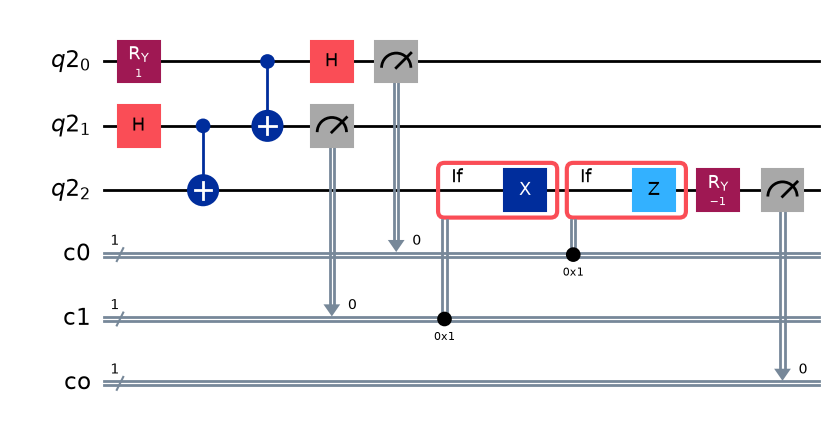

In [16]:
display(teleport(True).draw("mpl"))

**Bronze:** with the two classical bits, accuracy is **100%** → the state really arrives.
**Silver:** without the bits, accuracy drops to about **50%** (a coin toss) — Bob's qubit is no longer the message.
### Gold — without the classical bits, Bob's qubit carries no information about the message

In [17]:
def bob_p1(angle, corrected, shots=4000):
    q=QuantumRegister(3); c0=ClassicalRegister(1,'c0'); c1=ClassicalRegister(1,'c1'); co=ClassicalRegister(1,'co')
    qc=QuantumCircuit(q,c0,c1,co)
    qc.ry(angle,q[0]); qc.h(q[1]); qc.cx(q[1],q[2]); qc.cx(q[0],q[1]); qc.h(q[0])
    qc.measure(q[0],c0); qc.measure(q[1],c1)
    if corrected:
        with qc.if_test((c1,1)): qc.x(q[2])
        with qc.if_test((c0,1)): qc.z(q[2])
    qc.measure(q[2],co)
    c = run(qc, shots)
    return sum(v for k,v in c.items() if k[0]=='1')/shots

for angle in [0, np.pi/3, 2*np.pi/3, np.pi]:
    print(f"message angle {angle:.2f}: target P(1)={np.sin(angle/2)**2:.2f} | "
          f"Bob with bits {bob_p1(angle, True):.2f} | Bob without bits {bob_p1(angle, False):.2f}")

message angle 0.00: target P(1)=0.00 | Bob with bits 0.00 | Bob without bits 0.51


message angle 1.05: target P(1)=0.25 | Bob with bits 0.26 | Bob without bits 0.50


message angle 2.09: target P(1)=0.75 | Bob with bits 0.75 | Bob without bits 0.50


message angle 3.14: target P(1)=1.00 | Bob with bits 1.00 | Bob without bits 0.50


**Proves:** without the two classical bits, Bob sees **≈ 0.50 for every message** — his qubit alone tells him nothing. Useful information only arrives with the classical bits, which travel at light speed or slower. **ECHO was never faster than light.**

## Verdict (summary — full reasoning in `Case_Report.md`)
ECHO's detectors were correlated, never communicating. Zara mistook an echo for a voice — and the biased seed (Module 02) shows the run was triggered by a deliberately chosen, non-random setting.